# Notebook 3, Beilage: Ausreisserregeln

**Statistik für Data Science** · Kurs 3,906 · Bachelor Computer Science · HS2026
Universität St. Gallen · Begleitmaterial zur Übung

---

Dieses Begleitnotebook zu **NB03 (Robuste Verteilungsdiagnostik)** vertieft die Ausreisserregeln, die die Vorlesung ausdrücklich in die Übung verweist. Es ist ein Werkzeug für eure Projektarbeit: Kandidaten markieren, prüfen und die Entscheidung dokumentieren. Die Code-Abschnitte folgen denselben vier Schritten wie NB02 und NB03.

**Die vier Schritte.** Sie kehren in jedem Code-Abschnitt in derselben Reihenfolge wieder:

| Schritt | Was dort steht |
|---|---|
| **Problem.** | Eine konkrete Frage, meist mit einer Zahl aus den Daten |
| **Theorie.** | Was die Vorlesung dazu sagt, mit der Folie: *Vorlesung: Folie «…»* |
| **Code.** | `# Rechnen` berechnet die Statistik, `# Darstellen` zeigt vorher und nachher |
| **Bedeutung.** | Was der Output zeigt und welche Entscheidung daraus folgt |
| **Euer Datensatz.** | Dieselbe Frage für eure eigene Variable |

**Übersicht.** Dieses Notebook wird nicht in der Übung gezeigt; es ist Material für das Selbststudium und die Projektarbeit.

| | Abschnitt | Problem |
|---|---|---|
| 1 | Entscheidungskarte | Welches Werkzeug beantwortet welche Frage? |
| 2 | Drei Ausreisserregeln | Sind markierte Werte automatisch Fehler? |
| 3 | Von der Markierung zur Entscheidung | Wie wird aus einer Markierung eine dokumentierte Entscheidung? |

**Datensatz.** Die Titanic-Ticketpreise führen NB02 und NB03 fort: rechtsschief, mit schwerem rechtem Tail und gemischten Klassen, also genau der Fall, in dem Markierungsregeln auseinanderlaufen.

## 0. Setup

Es gelten dieselben Konventionen wie in NB01 bis NB03: wenige Standardpakete und ein zentraler Seed. Gebraucht wird hier nur der Titanic-Datensatz.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
RNG = np.random.default_rng(SEED)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (7.5, 4.2)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [2]:
titanic = sns.load_dataset('titanic')
fare = titanic['fare'].dropna()

print(f'Titanic: {titanic.shape[0]} Zeilen, {titanic.shape[1]} Spalten')
print(f'Ticketpreise: n = {len(fare)}, fehlend = {titanic["fare"].isna().sum()}')

Titanic: 891 Zeilen, 15 Spalten
Ticketpreise: n = 891, fehlend = 0


---

## 1. Entscheidungskarte

*Vertiefung zur Vorlesung. Leitfrage: Welches Werkzeug beantwortet welche Frage?*

Diese Karte ist der schnelle Einstieg für die Projektarbeit: von der Beobachtung zum sinnvollen nächsten Schritt. Alles, was hier steht, wird in NB03 (Plots und ihre Parameter) oder in den Abschnitten 2 und 3 dieses Notebooks (Regeln und Fallnotiz) gerechnet.

| Beobachtung oder Frage | Sinnvoller nächster Schritt | Was daraus nicht folgt |
|---|---|---|
| einzelne extreme Werte | Quelle und Einheit prüfen; Tukey und modifizierten z-Score **je sinnvoller Gruppe** vergleichen (Abschnitt 2) | «markiert» bedeutet nicht «falsch» |
| ungefähr symmetrische, normalnahe Daten | gewöhnlicher z-Score als zusätzlicher Schnellcheck (Abschnitt 2) | eine Schwelle wie 3 ist kein Naturgesetz |
| schiefe Daten oder empfindliche SD | Tukey-Zäune und modifizierter z-Score; Median, IQR und MAD berichten (NB02 2.5) | eine robuste Regel macht einen Wert nicht automatisch zum Fehler |
| starke Rechtsschiefe | Rohskala behalten; Log-Skala als klar gekennzeichnete Zusatzsicht (NB03 2.3); QQ-Plot prüfen (NB03 3.2) | die Log-Skala ist keine Datenbereinigung |
| Gruppenvergleich | Boxplot plus Rohdatenpunkte; Violine für die Form (NB03 2.4); n je Gruppe nennen | Box, Violine oder Kerbe allein beweisen keinen Unterschied |
| Ergebnis berichten | Einheit, n, fehlende Werte, Gruppe, Regel samt Parametern, Kandidatenzahl, Entscheidung und Sensitivität nennen (Abschnitt 3; NB03 3.4) | ein Plot ohne Parameter ist nicht reproduzierbar |

**Häufige Fehler, bevor der erste Plot entsteht.**

1. Eine Markierungsregel mit einer Fehlerdiagnose verwechseln.
2. Einen z-Score auf stark schiefe Daten anwenden und die Normalitätsidee dahinter ignorieren.
3. Globale Grenzen verwenden, obwohl Gruppen verschiedene Lagen oder Streuungen haben.
4. Werte still löschen, überschreiben oder winsorisieren, ohne Rohspalte und Fall-ID zu behalten.
5. Bins oder Bandbreite so lange verändern, bis die gewünschte Geschichte sichtbar ist.
6. Eine KDE oder Violine bei kleinem n wie beobachtete Rohdaten lesen.
7. Null- oder negative Werte bei einer Log-Skala still verlieren.
8. Median mit Mittelwert, Boxhöhe mit SD oder Whisker mit Minimum und Maximum verwechseln.
9. Nicht überlappende Kerben als formalen Test ausgeben.
10. Einheit, Gruppengrösse, fehlende Werte oder Plotparameter im Bericht weglassen.

**Minimaler Arbeitsablauf:** Rohdaten unverändert sichern, Fall-ID behalten, Verteilung und Gruppen ansehen, mehrere Diagnosewerkzeuge vergleichen, Quelle prüfen, Entscheidung begründen, Kennzahlen mit und ohne Eingriff als Sensitivität vergleichen, Fallnotiz schreiben.

> **Euer Datensatz.** Welche Zeile der Karte trifft eure Variable in dieser Woche, und welcher nächste Schritt folgt daraus?

---

## 2. Drei Ausreisserregeln

**Problem.** Dieselben 891 Titanic-Ticketpreise liefern je nach Regel 20, 116 oder 160 Markierungen. Welche Regel hat recht?

**Theorie.** *Vertiefung zur Vorlesung: Folien «Boxplot: Anatomie», «Whisker?», «Fallen beim Lesen»; MAD aus NB02 2.5*

Drei verbreitete Regeln, drei Vorstellungen von «weit weg»:

- **z-Score:** $z_i = \frac{x_i - \bar{x}}{s}$, übliche Schwelle $|z| > 3$. Sinnvoll als Schnellcheck bei ungefähr symmetrischen, normalnahen Daten; Mittelwert und SD reagieren aber selbst auf Extreme.
- **Tukey-Zäune:** markiert ist, was unter $Q_1 - 1.5 \cdot IQR$ oder über $Q_3 + 1.5 \cdot IQR$ liegt. Robust und ohne Normalannahme; bei Schiefe oder schweren Tails werden viele legitime Randwerte markiert (NB03 2.1).
- **Modifizierter z-Score:** $M_i = \frac{0.6745 \, (x_i - \tilde{x})}{MAD}$, übliche Schwelle $|M| > 3.5$. Median $\tilde{x}$ und MAD sind robust; bei $MAD = 0$ ist die Regel nicht definiert und braucht eine andere Lösung.

Aus jeder Schwelle folgt eine Grenze in Werten; beim modifizierten z-Score heisst $|M| > 3.5$ umgestellt $|x - \tilde{x}| > 3.5 \cdot MAD / 0.6745$, so entstehen die Grenzen in der Tabelle unten.

Alle drei sind **Screening-Regeln**: Sie finden mathematisch ungewöhnliche Werte relativ zu einer Referenz, keine Messfehler.

**Code.** Alle drei Regeln explizit auf den Ticketpreisen, dann die Überlappung der drei Markierungen. Die Grafik zeigt dieselben 891 Werte dreimal als Punktstreifen, mit der oberen Grenze der jeweiligen Regel; die unteren Grenzen liegen bei allen drei Regeln im negativen Bereich und damit ausserhalb des Bildes.

In [3]:
# Rechnen
mittelwert = fare.mean()
sd = fare.std(ddof=1)
z = (fare - mittelwert) / sd
z_markiert = z.abs() > 3

q1, q3 = fare.quantile([0.25, 0.75])
iqr = q3 - q1
tukey_unten, tukey_oben = q1 - 1.5 * iqr, q3 + 1.5 * iqr
tukey_markiert = (fare < tukey_unten) | (fare > tukey_oben)

median = fare.median()
mad = (fare - median).abs().median()
m = 0.6745 * (fare - median) / mad
m_markiert = m.abs() > 3.5
robuste_skala = mad / 0.6745            # |M| > 3.5 entspricht |x - Median| > 3.5 · MAD/0.6745

uebersicht = pd.DataFrame(
    {
        'untere Grenze': [mittelwert - 3 * sd, tukey_unten, median - 3.5 * robuste_skala],
        'obere Grenze': [mittelwert + 3 * sd, tukey_oben, median + 3.5 * robuste_skala],
        'markiert': [z_markiert.sum(), tukey_markiert.sum(), m_markiert.sum()],
        'Anteil': [z_markiert.mean(), tukey_markiert.mean(), m_markiert.mean()],
    },
    index=['z-Score, |z| > 3', 'Tukey, 1.5·IQR', 'mod. z-Score, |M| > 3.5'],
)
uebersicht.round(3)

,untere Grenze,obere Grenze,markiert,Anteil
"z-Score, |z| > 3",-116.876,181.284,20,0.022
"Tukey, 1.5·IQR",-26.724,65.634,116,0.130
"mod. z-Score, |M| > 3.5",-21.372,50.280,160,0.180


In [4]:
# Rechnen
# & heisst «und», ~ heisst «nicht», beides elementweise auf den Wahr/Falsch-Spalten
print(f'von allen drei Regeln markiert:              '
      f'{(z_markiert & tukey_markiert & m_markiert).sum()}')
print(f'nur von den beiden robusten Regeln markiert: '
      f'{(~z_markiert & tukey_markiert & m_markiert).sum()}')
print(f'nur vom modifizierten z-Score markiert:      '
      f'{(~z_markiert & ~tukey_markiert & m_markiert).sum()}')
print(f'von keiner Regel markiert:                   '
      f'{(~z_markiert & ~tukey_markiert & ~m_markiert).sum()}')

von allen drei Regeln markiert:              20
nur von den beiden robusten Regeln markiert: 96
nur vom modifizierten z-Score markiert:      44
von keiner Regel markiert:                   731


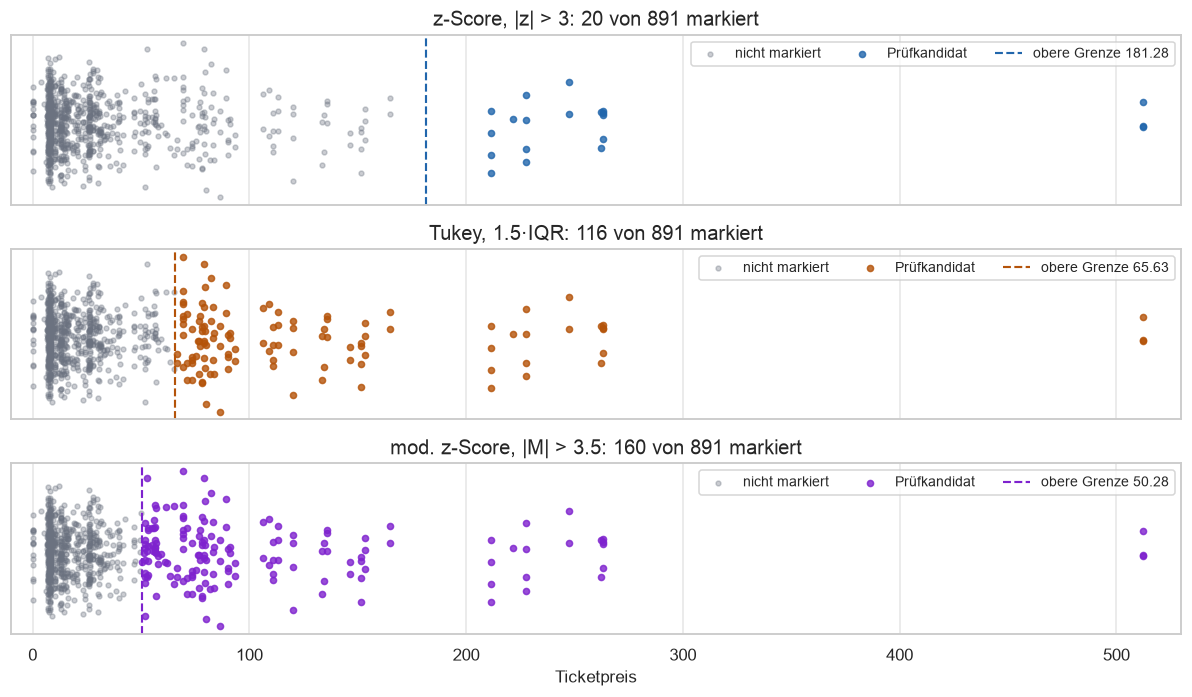

In [5]:
# Darstellen
rng_jitter = np.random.default_rng(SEED)
jitter = rng_jitter.normal(0, 0.03, len(fare))

# Werte und Markierungen einmal als NumPy-Arrays, dann ist die Indizierung überall gleich
fare_werte = fare.to_numpy()
z_maske = z_markiert.to_numpy()
tukey_maske = tukey_markiert.to_numpy()
m_maske = m_markiert.to_numpy()

fig, achsen = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)

achsen[0].scatter(fare_werte[~z_maske], jitter[~z_maske], s=10, color='#6B7280', alpha=0.35,
                  label='nicht markiert')
achsen[0].scatter(fare_werte[z_maske], jitter[z_maske], s=16, color='#2166AC', alpha=0.8,
                  label='Prüfkandidat')
achsen[0].axvline(mittelwert + 3 * sd, color='#2166AC', linestyle='--', linewidth=1.4,
                  label=f'obere Grenze {mittelwert + 3 * sd:.2f}')
achsen[0].set(title=f'z-Score, |z| > 3: {z_maske.sum()} von {len(fare)} markiert',
              yticks=[], ylabel='')
achsen[0].legend(loc='upper right', ncols=3, fontsize=9)

achsen[1].scatter(fare_werte[~tukey_maske], jitter[~tukey_maske], s=10, color='#6B7280',
                  alpha=0.35, label='nicht markiert')
achsen[1].scatter(fare_werte[tukey_maske], jitter[tukey_maske], s=16, color='#B45309',
                  alpha=0.8, label='Prüfkandidat')
achsen[1].axvline(tukey_oben, color='#B45309', linestyle='--', linewidth=1.4,
                  label=f'obere Grenze {tukey_oben:.2f}')
achsen[1].set(title=f'Tukey, 1.5·IQR: {tukey_maske.sum()} von {len(fare)} markiert',
              yticks=[], ylabel='')
achsen[1].legend(loc='upper right', ncols=3, fontsize=9)

achsen[2].scatter(fare_werte[~m_maske], jitter[~m_maske], s=10, color='#6B7280', alpha=0.35,
                  label='nicht markiert')
achsen[2].scatter(fare_werte[m_maske], jitter[m_maske], s=16, color='#7E22CE', alpha=0.8,
                  label='Prüfkandidat')
achsen[2].axvline(median + 3.5 * robuste_skala, color='#7E22CE', linestyle='--', linewidth=1.4,
                  label=f'obere Grenze {median + 3.5 * robuste_skala:.2f}')
achsen[2].set(title=f'mod. z-Score, |M| > 3.5: {m_maske.sum()} von {len(fare)} markiert',
              yticks=[], ylabel='')
achsen[2].legend(loc='upper right', ncols=3, fontsize=9)

achsen[-1].set(xlabel='Ticketpreis', xlim=(-10, 530))
plt.tight_layout()
plt.show()

**Bedeutung.** Keine Regel hat allein recht. Der z-Score markiert 20 Preise, Tukey 116, der modifizierte z-Score 160, und die Überlappung zeigt: Alle 20 z-Score-Fälle werden auch von beiden robusten Regeln markiert; die robusten Regeln markieren zusätzlich grosse Teile der legitimen rechten Flanke. Der Grund ist die Form: Die Ticketpreise sind rechtsschief und mischen Klassen (NB03), eine symmetrische Grenze um Mittelwert oder Median passt dazu schlecht. Vor jeder Fallprüfung gehören die Grenzen deshalb mindestens je fachlich sinnvoller Gruppe gerechnet, wie in NB02 2.4 die Zäune je Klasse.

> **Euer Datensatz.** Berechnet die drei Regeln für eure metrische Variable, und wo sinnvoll je Gruppe. Wo stimmen sie überein, wo nicht, und welche Formannahme erklärt den Unterschied?

> **Take-Home Ausreisserregeln**
>
> 1. Regeln markieren **Prüfkandidaten**, keine Fehler.
> 2. z-Score, Tukey und modifizierter z-Score beantworten verschiedene Distanzfragen; die gewählte Regel gehört mit Parametern in den Bericht.
>
> Bei schiefen Daten führen symmetrische Regeln in die Irre: erst die Form ansehen (NB03), dann die Regel wählen.

---

## 3. Von der Markierung zur Entscheidung

**Problem.** Der höchste Ticketpreis 512.33 wird von allen drei Regeln markiert. Was darf der Code jetzt tun?

**Theorie.** *Vertiefung zur Vorlesung: Folien «Mini-Case: Unterschied oder Ausreisser?», «Kombinierte Diagnostik», «Fallen beim Lesen»*

Die Reihenfolge ist fachlich, nicht algorithmisch:

1. **Prüfen:** Fall-ID, Quelle, Einheit, Messbereich, Duplikate und Erfassungsprozess kontrollieren.
2. **Korrigieren:** nur, wenn die richtige Information aus einer verlässlichen Quelle bekannt ist; den Rohwert erhalten.
3. **Behalten:** bei einem plausiblen seltenen Fall; robuste Kennzahlen berichten (NB02 2.5).
4. **Nur die Darstellung anpassen:** etwa mit der Log-Skala aus NB03 2.3; die Werte bleiben unverändert.
5. **Winsorisieren oder Trimmen:** nur mit fachlicher Begründung, als neue Spalte und als Sensitivitätsanalyse (NB02 1.3).
6. **Ausschliessen:** nur bei belegtem Datenfehler oder vorab definierter Regel, nie weil das Ergebnis bequemer wird.

Eine **Fallnotiz** hält mindestens fest: Fall-ID, Variable und Einheit, Regel mit Parametern und Vergleichsgruppe, beobachteter Wert, Quellenprüfung, Entscheidung, Begründung und Einfluss auf das Ergebnis.

**Entscheidungshilfe: fünf Prüffragen in fester Reihenfolge.** Die sechs Strategien sind das Menü; welche davon greift, entscheidet ihr, indem ihr für jeden markierten Wert diese Fragen von oben nach unten durchgeht. Die erste Frage, die greift, bestimmt die Strategie.

1. **Kann der Wert überhaupt vorkommen?** Messbereich und Vorzeichen prüfen (negative Dauern, ein Alter über 120), und die typischen Platzhalter kennen: 999, −1 oder 0 stehen in realen Datensätzen oft für «unbekannt». Ob die 15 Nullpreise der Titanic echte Gratis-Tickets oder ein solcher Code sind, ist genau diese Frage (NB03 2.3). Unmöglich heisst belegter Fehler: korrigieren, wenn die Quelle den richtigen Wert kennt, sonst dokumentiert ausschliessen.
2. **Stimmen Einheit und Erfassung?** Einheitenwechsel (Rappen statt Franken, cm statt m), Duplikate, Import-Artefakte wie verschobene Spalten. Ein solcher Fehler wird behoben; Rohwert und Fall-ID bleiben erhalten.
3. **Ist der Wert im richtigen Vergleich noch auffällig?** Grenzen je fachlich sinnvoller Gruppe rechnen statt global: Ein Ticketpreis um 30 ist über alle Passagiere unauffällig, in der dritten Klasse auffällig (NB02 2.4). Löst sich die Auffälligkeit auf, wird der Wert behalten und die Vergleichsgruppe im Bericht genannt.
4. **Passt der Wert zu einem plausiblen Prozess?** Preise, Einkommen, Wartezeiten und Latenzen haben legitime schwere rechte Flanken (NB03 3.3); seltene grosse Fälle gehören dann zur Verteilung. Plausibel heisst behalten und robuste Kennzahlen berichten.
5. **Immer noch unklar?** Dann gilt der Default: behalten, Fallnotiz schreiben, Kennzahlen mit und ohne den Fall als Sensitivität vergleichen. Nie still löschen.

**Merksatz: Im Zweifel behalten, robust berichten, dokumentieren.**

**Code.** Eine Fallnotiz für das Maximum, dann die Sensitivität: Kennzahlen im Rohdatensatz, ohne diesen einen Fall und nach Tukey-Winsorisierung. Die Grafik zeigt vorher die Rohdaten und nachher die winsorisierte Reihe mit dem Stau an der Zaun-Grenze.

In [6]:
# Rechnen
fall_id = fare.idxmax()
gleiche_faelle = titanic.index[titanic['fare'] == fare.max()].tolist()
print(f'Fälle mit dem Maximalwert {fare.max():.2f}: {gleiche_faelle}')

fallnotiz = pd.Series(
    {
        'Fall-ID': int(fall_id),
        'Variable / Einheit': 'fare / Einheit im Datensatz nicht dokumentiert',
        'Wert': fare.loc[fall_id],
        'Besonderheit': f'{len(gleiche_faelle)} Fälle teilen exakt diesen Wert: {gleiche_faelle}',
        'Regeln': 'markiert von z-Score, Tukey und modifiziertem z-Score (Abschnitt 2)',
        'Vergleichsgruppe': 'zunächst alle Passagiere; Klasse zusätzlich prüfen',
        'Quellenprüfung': 'im Übungsdatensatz nicht möglich',
        'Entscheidung': 'behalten, nicht automatisch ändern',
        'Begründung': 'Markierung beweist keinen Erfassungsfehler; drei identische Preise sprechen für einen Gruppenpreis',
        'Sensitivität': 'Rohdaten, ohne diesen Fall und winsorisiert vergleichen',
    },
    name='Fallnotiz',
)
fallnotiz.to_frame()

Fälle mit dem Maximalwert 512.33: [258, 679, 737]


,Fallnotiz
Fall-ID,258
Variable / Einheit,fare / Einheit im Datensatz nicht dokumentiert
Wert,512.3292
Besonderheit,"3 Fälle teilen exakt diesen Wert: [258, 679, 737]"
Regeln,"markiert von z-Score, Tukey und modifiziertem ..."
Vergleichsgruppe,zunächst alle Passagiere; Klasse zusätzlich pr...
Quellenprüfung,im Übungsdatensatz nicht möglich
Entscheidung,"behalten, nicht automatisch ändern"
Begründung,Markierung beweist keinen Erfassungsfehler; dr...
Sensitivität,"Rohdaten, ohne diesen Fall und winsorisiert ve..."


In [7]:
# Rechnen
ohne_maximum = fare.drop(index=fall_id)
winsorisiert = fare.clip(lower=tukey_unten, upper=tukey_oben)

sensitivitaet = pd.DataFrame(
    {
        'n': [len(fare), len(ohne_maximum), len(winsorisiert)],
        'Mittelwert': [fare.mean(), ohne_maximum.mean(), winsorisiert.mean()],
        'Median': [fare.median(), ohne_maximum.median(), winsorisiert.median()],
        'SD (ddof=1)': [fare.std(ddof=1), ohne_maximum.std(ddof=1), winsorisiert.std(ddof=1)],
        'IQR': [iqr, ohne_maximum.quantile(0.75) - ohne_maximum.quantile(0.25),
                winsorisiert.quantile(0.75) - winsorisiert.quantile(0.25)],
    },
    index=['Rohdaten', f'ohne Fall {fall_id}', 'Tukey-winsorisiert'],
)
print(f'Die Winsorisierung verändert {(fare != winsorisiert).sum()} von {len(fare)} Werten.')
sensitivitaet.round(2)

Die Winsorisierung verändert 116 von 891 Werten.


,n,Mittelwert,Median,SD (ddof=1),IQR
Rohdaten,891,32.20,14.45,49.69,23.09
ohne Fall 258,890,31.66,14.45,47.04,23.10
Tukey-winsorisiert,891,24.05,14.45,20.48,23.09


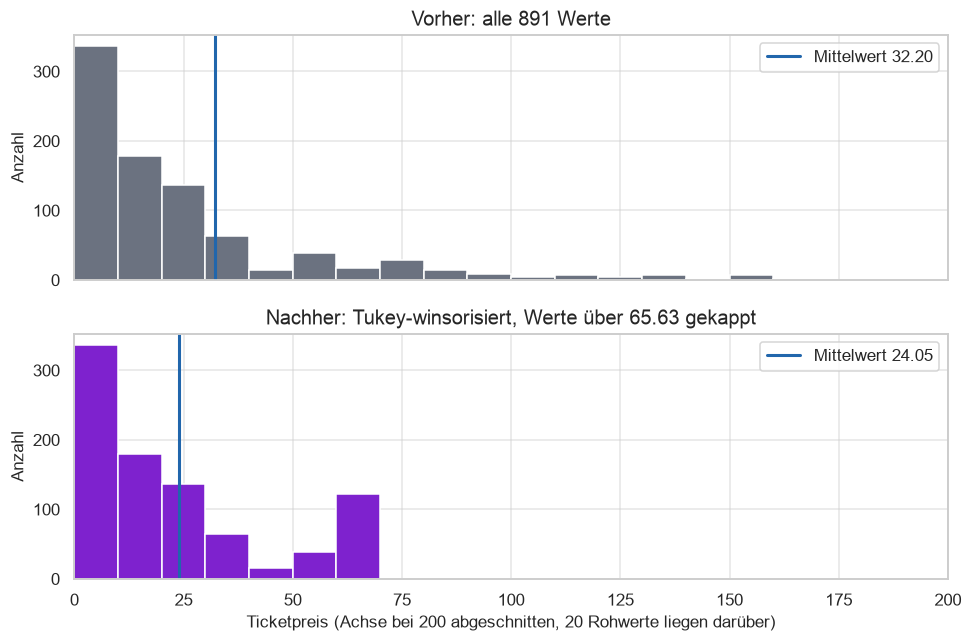

In [8]:
# Darstellen
klassen = np.arange(0, 540, 10)

fig, achsen = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, werte, titel, farbe in zip(
    achsen,
    [fare, winsorisiert],
    [f'Vorher: alle {len(fare)} Werte',
     f'Nachher: Tukey-winsorisiert, Werte über {tukey_oben:.2f} gekappt'],
    ['#6B7280', '#7E22CE'],
):
    ax.hist(werte, bins=klassen, color=farbe, edgecolor='white')
    ax.axvline(werte.mean(), color='#2166AC', linewidth=2, label=f'Mittelwert {werte.mean():.2f}')
    ax.set(title=titel, ylabel='Anzahl')
    ax.legend(loc='upper right')
achsen[-1].set(xlabel=f'Ticketpreis (Achse bei 200 abgeschnitten, '
                      f'{(fare > 200).sum()} Rohwerte liegen darüber)', xlim=(0, 200))
plt.tight_layout()
plt.show()

**Bedeutung.** Das Entfernen des einen Falls 258 bewegt Mittelwert und SD sichtbar, Median und IQR dagegen kaum. Und die Prüffragen zahlen sich sofort aus: Der Maximalwert kommt dreimal vor (Fälle 258, 679 und 737), drei identische Tickets sprechen für einen Gruppenpreis und gegen einen Tippfehler. Die Tukey-Winsorisierung verändert 116 von 891 Werten und staut sie an der Grenze 65.63: Das ist keine harmlose Bereinigung, sondern ein Eingriff, der die Frage verändert. Die vertretbare Entscheidung im Übungsdatensatz steht in der Fallnotiz: behalten, robuste Kennzahlen berichten, Sensitivität dokumentieren. Erst eine externe Quelle könnte belegen, dass 512.33 falsch ist.

> **Euer Datensatz.** Wählt einen markierten Fall und schreibt die Fallnotiz. Welche Quelle könnte den Wert bestätigen, und wie ändern sich eure Kennzahlen mit und ohne den Fall?

> **Take-Home Fallnotiz**
>
> 1. Rohdaten und Fall-ID bleiben erhalten; Änderungen entstehen in neuen Spalten.
> 2. Jede Entscheidung braucht Quellenprüfung, Begründung und Sensitivitätsanalyse.
> 3. Die Fallnotiz macht den Prozess reproduzierbar.
>
> Markieren ist der Anfang der Prüfung, nicht ihr Ende.

---

## 4. Was ihr mit eurem eigenen Datensatz macht

**1. Regeln rechnen und vergleichen.** Berechnet z-Score, Tukey-Zäune und modifizierten z-Score für eure metrische Variable, und wo sinnvoll je Gruppe. Nennt Grenzen und Kandidatenzahl je Regel.

**2. Sonderfälle abfangen.** Prüft MAD = 0 (dann ist der modifizierte z-Score nicht definiert) und dokumentiert, wie ihr damit umgeht.

**3. Fallnotizen schreiben.** Geht für jeden Fall, den ihr genauer anschaut, erst die fünf Prüffragen aus Abschnitt 3 durch. Die Fallnotiz hält dann fest: Fall-ID, Wert, Regel samt Parametern, Quellenprüfung, Entscheidung, Begründung.

**4. Sensitivität statt Löschen.** Vergleicht Kennzahlen mit und ohne Eingriff nur als Sensitivitätsanalyse; die Rohdaten bleiben unverändert.

Die Diagnose-Routine und der Entscheidungssatz für das Log stehen in NB03, Abschnitt 3.4.